# Assignment 3
Due Sep. 23

Yazdan Zinati 
260928077   

Dataset with brain atlas A: for the first set of 5 small programming tasks use the Oasis
dataset provided by the nilearn package, which can be downloaded using the code below.
This is a dataset of structural brain scans (aka voxel-based morphometry) for male and
female individuals.

In [1]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib


def fetch_oasis_dataset(n_rois, debug=False):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(n_rois=n_rois)
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    if debug:
        print(
            "Fetched dataset.\n" "input variables shape:",
            input_variables.shape,
            "\n",
            "output variable shape",
            output_variable.shape,
        )
    return input_variables, output_variable

1. Use sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0)
to fit separate logistic predictive models based on 100, 200, 300, …, 900, 1000 brain
regions of interest (see ‘n_rois’ argument for datasets.fetch_atlas_schaefer_2018)
based on the first 80% of the 100 structural brain scans to predict sex differences.
Next, evaluate each fitted LogReg model on the unseen final 20% of the 100
structural brain scans and retrieve classification accuracy in XX.YY%. Please plot
the classification accuracy on the test set (x axis=the different atlas resolutions, y
axis=prediction accuracy on test set).

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

num_regions = range(100, 1100, 100)
scores = []

for n_rois in num_regions:
    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    classifier = LogisticRegression(max_iter=1000)
    classifier.fit(train_x, train_y)

    scores.append(classifier.score(test_x, test_y))

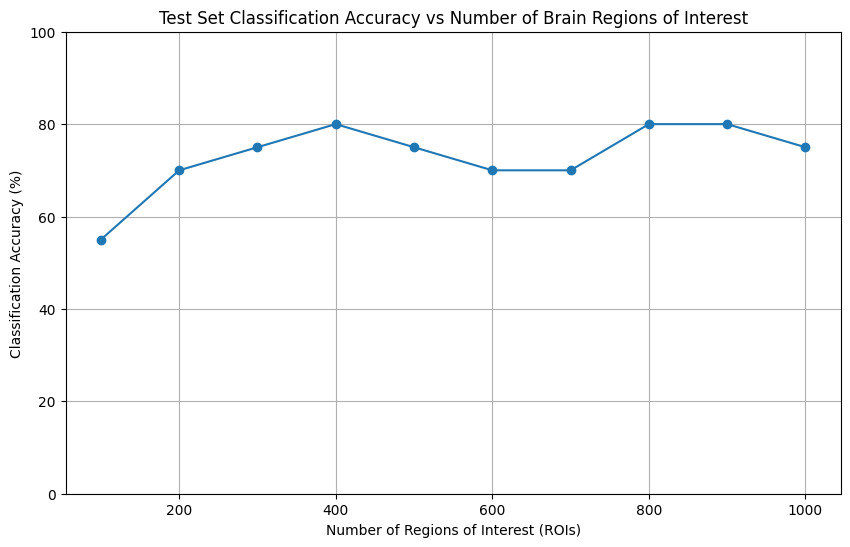

In [3]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(10, 6))
plt.plot(list(num_regions), np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of Brain Regions of Interest')
plt.xlabel('Number of Regions of Interest (ROIs)')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We do best with 400, 800, and 900 ROIs.

2. Based on 1000 brain regions of interest (see ‘n_rois’) and using the first 80% of
the 100 structural brain scans, use (sklearn.decomposition.PCA) with
n_components=1,2,3,4,…25 to perform principal component analysis and then
use sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0)
to fit separate logistic regression models to predict sex differences. The input
features for fitting the LogReg are only the component projections. Next, evaluate
each fitted LogReg model on the unseen final 20% of the 100 structural brain
scans and retrieve classification accuracy in XX.YY%. Please plot the classification
accuracy on the test set (x axis=the different numbers of PCA components, y
axis=prediction accuracy on test set).

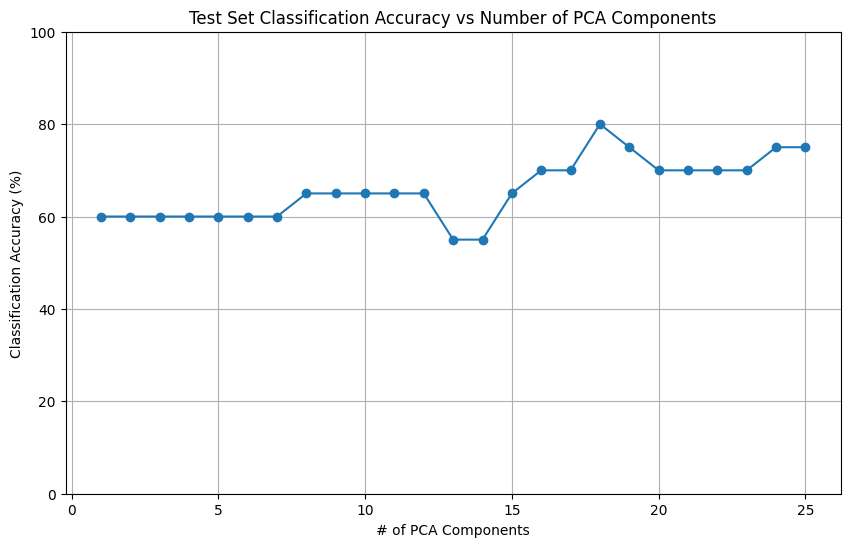

In [4]:
from sklearn.decomposition import PCA

pca_dims = range(1, 26)
num_regions = 1000

input_variables, output_variable = fetch_oasis_dataset(num_regions)

train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

scores = []

for pca_dim in pca_dims:
    pca = PCA(n_components=pca_dim)
    train_x_pca = pca.fit_transform(train_x)
    test_x_pca = pca.transform(test_x)

    classifier = LogisticRegression()
    classifier.fit(train_x_pca, train_y)
    
    scores.append(classifier.score(test_x_pca, test_y))

plt.figure(figsize=(10, 6))
plt.plot(pca_dims, np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of PCA Components')
plt.xlabel('# of PCA Components')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We have a peak at around 18 PCA components.

3. Based on 1000 brain regions of interest (see ‘n_rois’) and using the first 80% of
the 100 structural brain scans, use (sklearn.cluster.KMeans) to perform k
means clustering with n_clusters=1,2,3,4,…25. Then use
sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0) to
fit separate logistic regression models to predict sex differences. So, the inputfeatures for fitting the LogReg are only the cluster projections. Next, evaluate each
fitted LogReg model on the unseen final 20% of the 100 structural brain scans
and retrieve classification accuracy in XX.YY%. Please plot the classification
accuracy on the test set (x axis=the different numbers of k-means clusters, y
axis=prediction accuracy on test set).

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/st

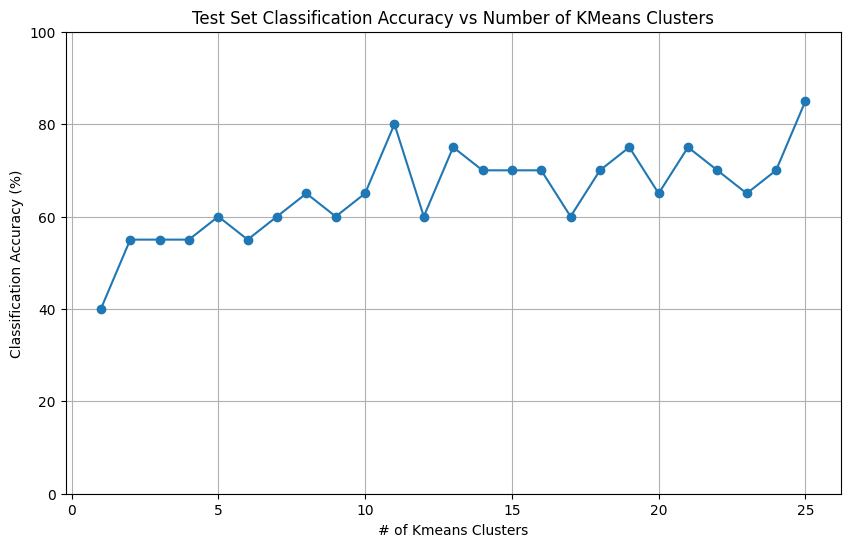

In [5]:
from sklearn.cluster import KMeans

ks = range(1, 26)
num_regions = 1000

input_variables, output_variable = fetch_oasis_dataset(num_regions)

train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

scores = []

for k in ks:
    kmeans = KMeans(n_clusters = k)
    train_x_kmeans = kmeans.fit_transform(train_x)
    test_x_kmeans = kmeans.transform(test_x)

    classifier = LogisticRegression()
    classifier.fit(train_x_kmeans, train_y)
    
    scores.append(classifier.score(test_x_kmeans, test_y))

plt.figure(figsize=(10, 6))
plt.plot(list(ks), np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of KMeans Clusters')
plt.xlabel('# of Kmeans Clusters')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

we do best with 25 clusters

4. Based on 1000 brain regions of interest (see ‘n_rois’) and using the first 80% of
the 100 structural brain scans, use
(sklearn.feature_selection.SelectKBest) and
(sklearn.feature_selection.f_classif) to perform feature selection with
the best k=2,4, 6, 8, 10 features. Then, use
sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0) to fit
separate logistic regression models to predict sex differences. So, the input features
for fitting the LogReg are only the k best single features, as identified on the training
data. Next, evaluate each fitted LogReg model on the unseen final 20% of the 100
structural brain scans and retrieve classification accuracy in XX.YY%. Please plot
the classification accuracy on the test set (x axis=the different numbers of k best
features, y axis=prediction accuracy on test set).

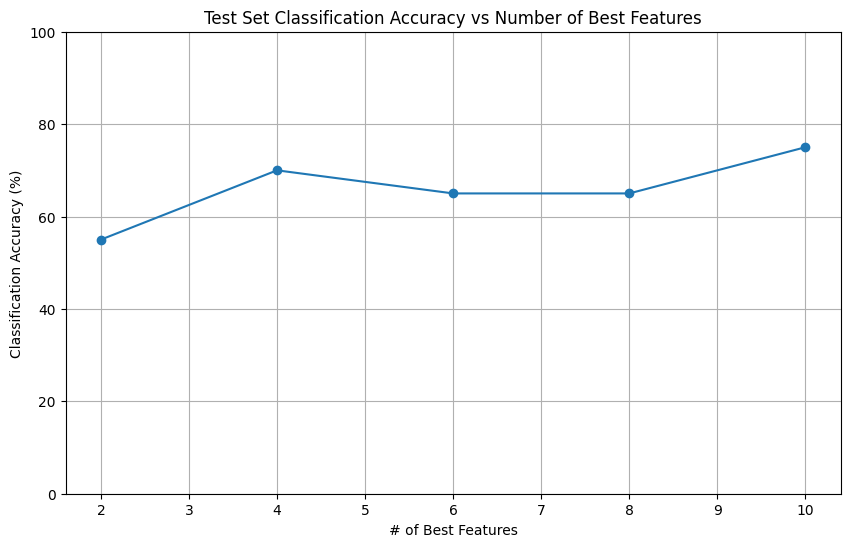

In [9]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif

ks = [2, 4, 6, 8, 10]
num_regions = 1000

input_variables, output_variable = fetch_oasis_dataset(num_regions)

# train_x, test_x, train_y, test_y = (
#     input_variables[:80],
#     input_variables[80:],
#     output_variable[:80],
#     output_variable[80:],
# )

train_idx, test_idx = train_test_split(np.arange(100), test_size=0.2, random_state=42, stratify=output_variable)
train_x, test_x = input_variables[train_idx], input_variables[test_idx]
train_y, test_y = output_variable[train_idx], output_variable[test_idx]


scores = []

for k in ks:
    selector = SelectKBest(score_func=f_classif, k=k)
    train_x_kbest = selector.fit_transform(train_x, train_y)
    test_x_kbest = selector.transform(test_x)


    classifier = LogisticRegression()
    classifier.fit(train_x_kbest, train_y)
    
    scores.append(classifier.score(test_x_kbest, test_y))

plt.figure(figsize=(10, 6))
plt.plot(ks, np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of Best Features')
plt.xlabel('# of Best Features')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We do best at 10 features. But there's a peak at 4 features that seems promising.

5. Use sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0)
to fit separate logistic predictive models based on 100, 200, 300, …, 900, 1000
brain regions of interest (see ‘n_rois’) based on the first 80% of the 100 structural
brain scans to predict sex differences. Use the probabilistic prediction of LogReg
(predict_proba function) from the training data from the 10 already obtained
LogReg models to fit a LogReg stacking model to predict sex. Next, evaluate the
final LogReg stacking model on the unseen final 20% of the 100 structural brain
scans and print classification accuracy in XX.YY%.

In [10]:
num_regions = range(100, 1100, 100)
scores = []


train_proba = []
test_proba = []


for n_rois in num_regions:
    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    classifier = LogisticRegression()
    classifier.fit(train_x, train_y)
    train_proba.append(classifier.predict_proba(train_x)[:, 1]) 
    test_proba.append(classifier.predict_proba(test_x)[:, 1])


train_proba = np.column_stack(train_proba)
test_proba = np.column_stack(test_proba)

stacking_model = LogisticRegression(C=1.0)
stacking_model.fit(train_proba, train_y)
score = stacking_model.score(test_proba, test_y)

In [11]:
print(f"classification accuracy: {score: .2f}")

classification accuracy:  0.75


Dataset with brain atlas B: For the second set of 5 small programming tasks use the Oasis
dataset provided by the nilearn package, which can be downloaded using the code below.
This is a dataset of structural brain scans (aka voxel-based morphometry) for male and
female individuals.

The download gave me ssl cert errors so I manually downloaded and loaded the craddock data

In [1]:
import os 
def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        'scorr_mean': os.path.join(base_path, 'scorr05_mean_all.nii.gz'),
        'tcorr_mean': os.path.join(base_path, 'tcorr05_mean_all.nii.gz'),
        'scorr_2level': os.path.join(base_path, 'scorr05_2level_all.nii.gz'),
        'tcorr_2level': os.path.join(base_path, 'tcorr05_2level_all.nii.gz'),
        'random': os.path.join(base_path, 'random_all.nii.gz'),
        'description': 'Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.'
    }
    return craddock_data


In [2]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib

def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    # Load your local brain data (adjust the path accordingly)
    # Assuming you have brain data as NIfTI files in a specific directory
    brain_data_dir = '/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/'

    # Load the Craddock atlas from local files
    crad = load_craddock_local(brain_data_dir)


    # crad = datasets.fetch_atlas_craddock_2012(url="https://www.nitrc.org/frs/downloadlink.php/3720")
    atlas_nii = index_img(crad["scorr_mean"], n_rois)  # this needs to bemodified for some tasks
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    return input_variables, output_variable

6. analogous to task 1, but using 43 different versions of Craddock region atlas
resolutions (.scorr_mean) instead of the 10 region numbers from Dataset A.

In [4]:
from sklearn.linear_model import LogisticRegression

versions = range(0, 43)

scores = []

for n_rois in versions:
    print(n_rois, end=',')
    input_variables, output_variable = fetch_second_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )
    
    classifier = LogisticRegression()
    classifier.fit(train_x, train_y)

    scores.append(classifier.score(test_x, test_y))

0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,

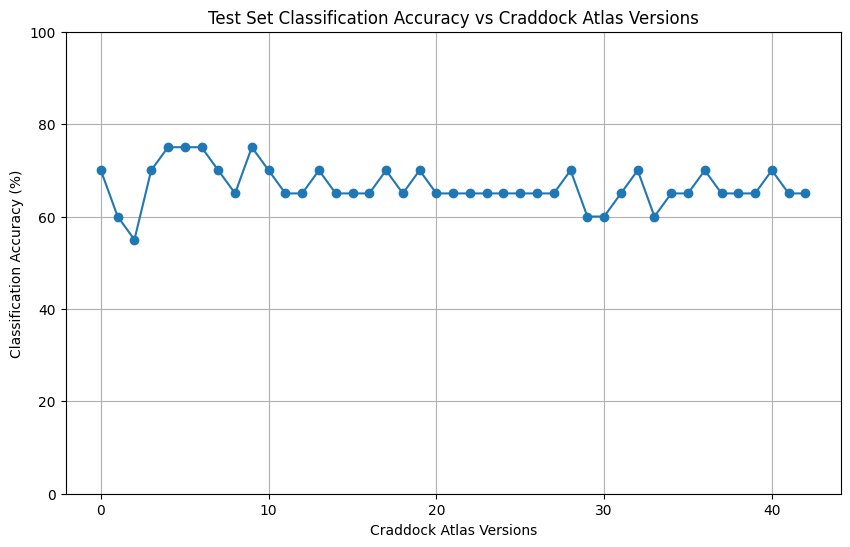

In [5]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(10, 6))
plt.plot(list(versions), np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Craddock Atlas Versions')
plt.xlabel('Craddock Atlas Versions')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We get the best performance with versions 5-7. 

7. analogous to task 2, but using version 43 of Craddock region atlas with highest
resolutions (.scorr_mean).

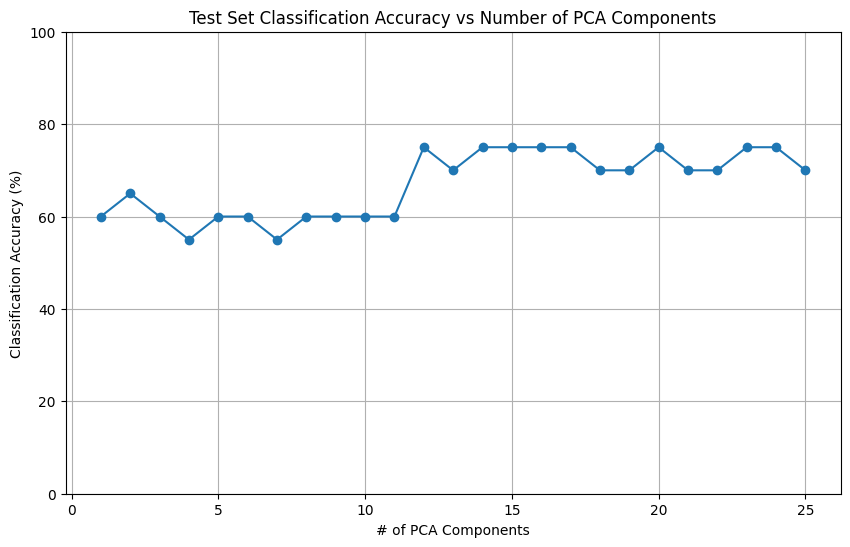

In [6]:
from sklearn.decomposition import PCA

pca_dims = range(1, 26)
num_regions = 42

input_variables, output_variable = fetch_second_dataset(num_regions)

train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

scores = []

for pca_dim in pca_dims:
    pca = PCA(n_components=pca_dim)
    train_x_pca = pca.fit_transform(train_x)
    test_x_pca = pca.transform(test_x)

    classifier = LogisticRegression()
    classifier.fit(train_x_pca, train_y)
    
    scores.append(classifier.score(test_x_pca, test_y))

plt.figure(figsize=(10, 6))
plt.plot(pca_dims, np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of PCA Components')
plt.xlabel('# of PCA Components')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

In general, more PCA components seem to help us. We see a peak at step 12.

8. analogous to task 3, but using version 43 of Craddock region atlas with highest
resolutions (.scorr_mean).

/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/bmde_env/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/st

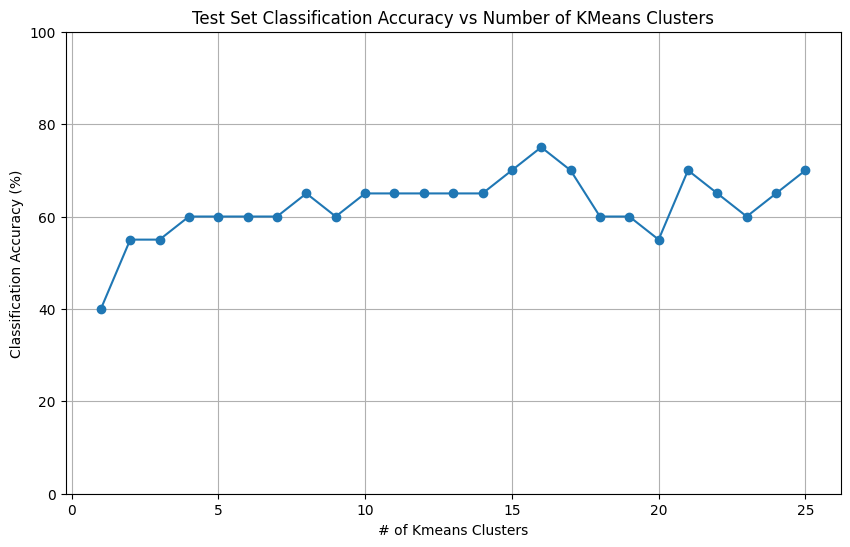

In [8]:
from sklearn.cluster import KMeans

ks = range(1, 26)
scores = []
for k in ks:
    kmeans = KMeans(n_clusters = k)
    train_x_kmeans = kmeans.fit_transform(train_x)
    test_x_kmeans = kmeans.transform(test_x)

    classifier = LogisticRegression()
    classifier.fit(train_x_kmeans, train_y)
    
    scores.append(classifier.score(test_x_kmeans, test_y))

plt.figure(figsize=(10, 6))
plt.plot(list(ks), np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of KMeans Clusters')
plt.xlabel('# of Kmeans Clusters')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We see a peak at 16 features. 

9. analogous to task 4, but using version 43 of Craddock region atlas with highest
resolutions (.scorr_mean).

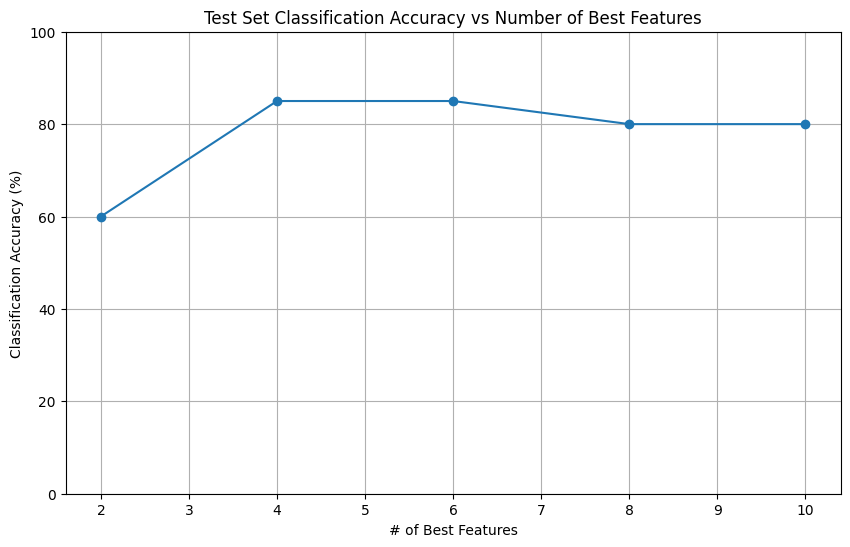

In [9]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif

ks = [2, 4, 6, 8, 10]

train_x, test_x, train_y, test_y = (
    input_variables[:80],
    input_variables[80:],
    output_variable[:80],
    output_variable[80:],
)

# train_idx, test_idx = train_test_split(np.arange(100), test_size=0.2, random_state=42, stratify=output_variable)
# train_x, test_x = input_variables[train_idx], input_variables[test_idx]
# train_y, test_y = output_variable[train_idx], output_variable[test_idx]


scores = []

for k in ks:
    selector = SelectKBest(score_func=f_classif, k=k)
    train_x_kbest = selector.fit_transform(train_x, train_y)
    test_x_kbest = selector.transform(test_x)


    classifier = LogisticRegression()
    classifier.fit(train_x_kbest, train_y)
    
    scores.append(classifier.score(test_x_kbest, test_y))

plt.figure(figsize=(10, 6))
plt.plot(ks, np.array(scores) * 100, marker='o')
plt.title('Test Set Classification Accuracy vs Number of Best Features')
plt.xlabel('# of Best Features')
plt.ylabel('Classification Accuracy (%)')
plt.ylim([0, 100])
plt.grid(True)
plt.show()

We see a peak at 4 features

10. analogous to task 5, but using the 43 different Craddock region atlas resolutions
(.scorr_mean) instead of the 10 region numbers from Dataset A.

In [11]:
versions = range(0, 43)
scores = []


train_proba = []
test_proba = []


for n_rois in versions:
    print(n_rois, end=',')
    input_variables, output_variable = fetch_second_dataset(n_rois)

    train_x, test_x, train_y, test_y = (
        input_variables[:80],
        input_variables[80:],
        output_variable[:80],
        output_variable[80:],
    )

    classifier = LogisticRegression()
    classifier.fit(train_x, train_y)
    train_proba.append(classifier.predict_proba(train_x)[:, 1]) 
    test_proba.append(classifier.predict_proba(test_x)[:, 1])


train_proba = np.column_stack(train_proba)
test_proba = np.column_stack(test_proba)

stacking_model = LogisticRegression(C=1.0)
stacking_model.fit(train_proba, train_y)
score = stacking_model.score(test_proba, test_y)

0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,

In [12]:
print(f"classification accuracy: {score: .2f}")

classification accuracy:  0.65
